# Chronological Ensemble Comparison

**IT5006 · Phase 3 — delivery lead time**

This companion records the single convex ensemble experiment. It shares the regression cohort and outer windows, rather than reusing random Phase 2 OOF predictions.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display
root = next(q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / "Phase_3"] if (q / "src/regression").is_dir())
sys.path.insert(0, str(root / "src"))
from regression import config as C
from regression.reporting import table, draw
from regression.pipeline import read
import matplotlib.pyplot as plt
pd.options.display.float_format = "{:,.4f}".format
print("Phase 3 regression — saved, frozen evidence")

Phase 3 regression — saved, frozen evidence


## Nested Temporal Construction

Within each outer training set, the last three available purchase months provide inner out-of-time predictions. Each base fit uses earlier purchases, the embargo and labels known at that inner cutoff. Meta labels must be known before the outer cutoff. Nonnegative weights sum to one and the intercept is zero. Base configurations were selected by the main outer CV, which limits the independence of this comparison.

In [2]:
display(table("stacking_inner_audit"))

,outer,inner_month,cutoff,meta_label_cutoff,train_n,meta_n,train_latest_label,meta_latest_label,overlap
0,fold1,2017-09,2017-09-01 00:00:00,2018-01-01 00:00:00,16725,4149,2017-08-29 22:26:04,2017-12-23 20:07:03,0
1,fold1,2017-10,2017-10-01 00:00:00,2018-01-01 00:00:00,20831,4475,2017-09-27 16:38:25,2017-12-27 21:06:58,0
2,fold1,2017-11,2017-11-01 00:00:00,2018-01-01 00:00:00,25136,3625,2017-10-31 19:48:22,2017-12-30 15:43:26,0
3,fold2,2017-10,2017-10-01 00:00:00,2018-02-01 00:00:00,20831,4477,2017-09-27 16:38:25,2018-01-09 18:55:47,0
4,fold2,2017-11,2017-11-01 00:00:00,2018-02-01 00:00:00,25136,7275,2017-10-31 19:48:22,2018-01-31 18:24:39,0
5,fold2,2017-12,2017-12-01 00:00:00,2018-02-01 00:00:00,29360,4552,2017-11-30 21:04:02,2018-01-31 23:45:08,0
6,fold3,2017-11,2017-11-01 00:00:00,2018-03-01 00:00:00,25136,7280,2017-10-31 19:48:22,2018-02-27 18:05:08,0
7,fold3,2017-12,2017-12-01 00:00:00,2018-03-01 00:00:00,29360,5502,2017-11-30 21:04:02,2018-02-27 21:16:48,0
8,fold3,2018-01,2018-01-01 00:00:00,2018-03-01 00:00:00,34246,4533,2017-12-30 15:43:26,2018-02-28 23:48:36,0
9,fold4,2017-12,2017-12-01 00:00:00,2018-04-01 00:00:00,29360,5510,2017-11-30 21:04:02,2018-03-27 01:57:14,0


## Outer Validation and Weights

,candidate,fold,ridge_weight,rf_weight,hgb_weight,val_n,val_mae,val_rmse,val_r2,val_bias,val_within3,meta_training_mae
0,Convex_stack,fold1,0.4062,0.2366,0.3572,7068,5.4070,8.9832,0.1973,-2.1781,0.4345,3.8981
1,Convex_stack,fold2,0.6470,0.3530,0.0000,6551,6.4810,10.4238,0.1623,-3.2243,0.3906,5.2663
2,Convex_stack,fold3,0.5691,0.4309,0.0000,6996,6.6258,10.1446,0.1854,-3.8661,0.4067,5.5493
3,Convex_stack,fold4,0.8108,0.1516,0.0376,6715,4.0189,5.3659,0.4264,1.0621,0.4649,5.4343
4,Convex_stack,fold5,1.0000,-0.0000,0.0000,4406,3.9528,4.8995,-0.2060,3.0709,0.4548,5.9629


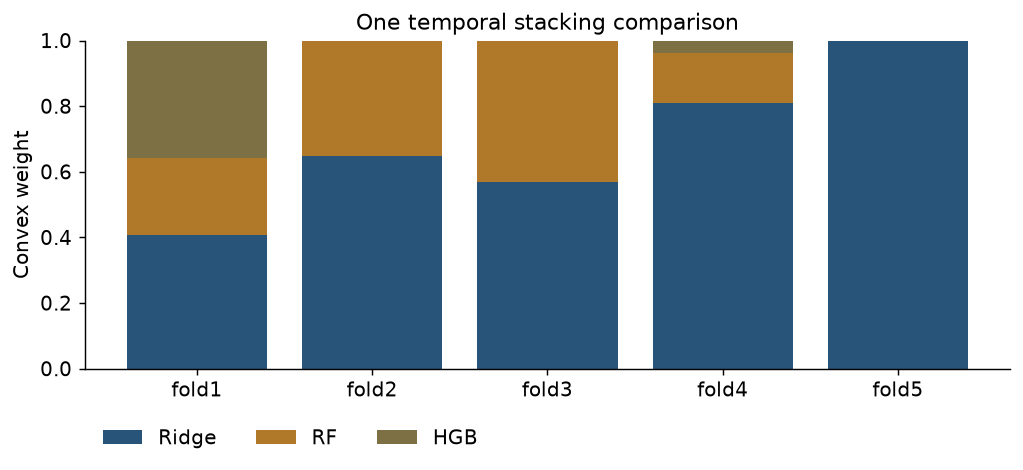

In [3]:
display(table("stacking_folds"))
draw("08_stack_weights"); plt.show()

## Retention Decision

A 1% reduction in mean validation MAE is required over the best single model. Discarded ensembles do not receive a final test score. No test result is used to revise weights or select another combination.

In [4]:
display(pd.Series(read("stacking_complete.json")))
display(table("train_cv_test_comparison"))

cv_mae                                                                 5.2971
cv_sd                                                                  1.2865
best_single_cv_mae                                                     5.2595
relative_gain                                                         -0.0071
retained                                                                False
threshold                                                              0.0100
base_configuration_scope    Base parameters selected using main five-month...
meta_rule                   Three recent inner expanding windows per outer...
dtype: object

,candidate,test_mae,train_mae,cv_mae,cv_sd,pooled_cv_mae,pooled_cv_rmse
0,Convex_stack,NaN,NaN,5.2971,1.2865,5.4018,8.5154
1,HGB_leaves15_l21,3.3969,4.7921,5.4140,2.0494,5.6191,9.2682
2,HGB_risk,3.4343,4.7190,5.2595,1.6386,5.4486,8.7657
3,Mean,6.6006,6.7601,7.1924,0.9719,7.2307,10.1332
4,Median,5.0603,6.4825,6.8824,1.6711,7.0199,10.3931
5,OLS,3.9111,5.2297,5.2900,1.2186,5.3896,8.3514
6,Promise,12.7181,12.6190,11.9915,1.5318,11.9821,13.9101
7,RF_d12_l80,4.1841,5.0905,5.4044,1.4978,5.5476,8.7507
8,Ridge_a100,3.8623,5.2397,5.2702,1.2454,5.3731,8.3456
9,Tree_d6_l30,4.2815,5.3562,5.5319,1.4980,5.6707,8.8510


## Reproducibility

Use the main regression pipeline through its `stacking` and `freeze` stages; raw data, inner predictions and fitted estimators are generated locally. The saved reading outputs are sufficient to inspect the reported comparison. See `docs/regression/report_evidence_guide.md` for interpretation and limitations.